# 03 · Production review

Reads the reports written by `churn simulate`: six months of cohorts with growing population shift, a corrupted delivery in April and labels that only arrive 30 days after scoring.
Run `make simulate` before this notebook.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110
import json

from churn import config

timeline = [json.loads(line) for line in (config.REPORTS_DIR / "timeline.jsonl").read_text().splitlines()]
promotions = [json.loads(line) for line in (config.REPORTS_DIR / "promotions.jsonl").read_text().splitlines()]

months = pd.DataFrame({
    "month": [r["as_of"] for r in timeline],
    "shift": [r["shift"] for r in timeline],
    "validation": ["quarantined" if "validation" in r else "ok" for r in timeline],
    "max_feature_psi": [r.get("drift", {}).get("max_feature_psi") for r in timeline],
    "prediction_psi": [r.get("drift", {}).get("prediction_psi") for r in timeline],
    "signals": [", ".join(r["signals"]) or "-" for r in timeline],
    "action": [r["retraining"]["action"] for r in timeline],
    "champion": [r["champion_after"] for r in timeline],
})
months

,month,shift,validation,max_feature_psi,prediction_psi,signals,action,champion
0,2026-01-01,0.0,ok,0.042,0.042,-,none,1
1,2026-02-01,0.0,ok,0.033,0.059,-,none,1
2,2026-03-01,1.0,ok,0.460,0.744,drift,promoted,2
3,2026-04-01,1.5,quarantined,NaN,NaN,-,none,2
4,2026-05-01,2.0,ok,0.322,0.547,drift,rejected,2
5,2026-06-01,2.0,ok,0.202,0.489,drift,promoted,4


## Drift

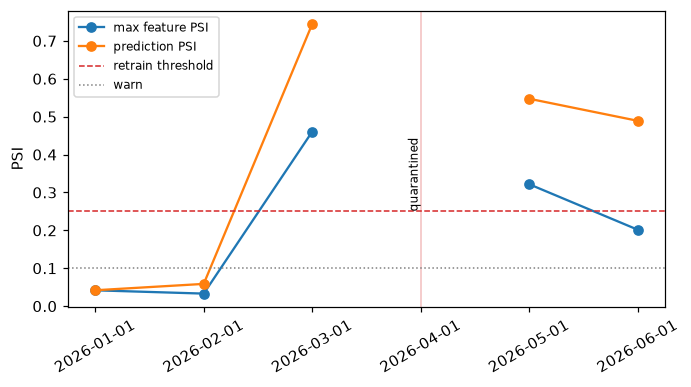

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(months["month"], months["max_feature_psi"], "o-", label="max feature PSI")
ax.plot(months["month"], months["prediction_psi"], "o-", label="prediction PSI")
ax.axhline(config.PSI_RETRAIN, color="C3", ls="--", lw=1, label="retrain threshold")
ax.axhline(config.PSI_WARN, color="grey", ls=":", lw=1, label="warn")
q = months["validation"] == "quarantined"
for m in months.loc[q, "month"]:
    ax.axvspan(m, m, color="C3", alpha=0.3)
    ax.annotate("quarantined", (m, config.PSI_RETRAIN), rotation=90, va="bottom", ha="right", fontsize=8)
ax.set_ylabel("PSI")
ax.legend(fontsize=8)
plt.xticks(rotation=30);

The score distribution moves more than any single feature, because the shift hits several correlated drivers at once (contract, internet service, payment method).
April has no drift reading: the delivery failed validation and was never scored.

## Realized performance with delayed labels

,snapshot_date,model_version,rows,gini,gini_ci95,churn_rate,predicted_churn_rate
0,2026-01-01,1,250,0.516,"[0.403, 0.6356]",0.268,0.260
2,2026-03-01,1,250,0.523,"[0.4016, 0.6374]",0.408,0.421
4,2026-05-01,2,250,0.622,"[0.5224, 0.713]",0.436,0.410


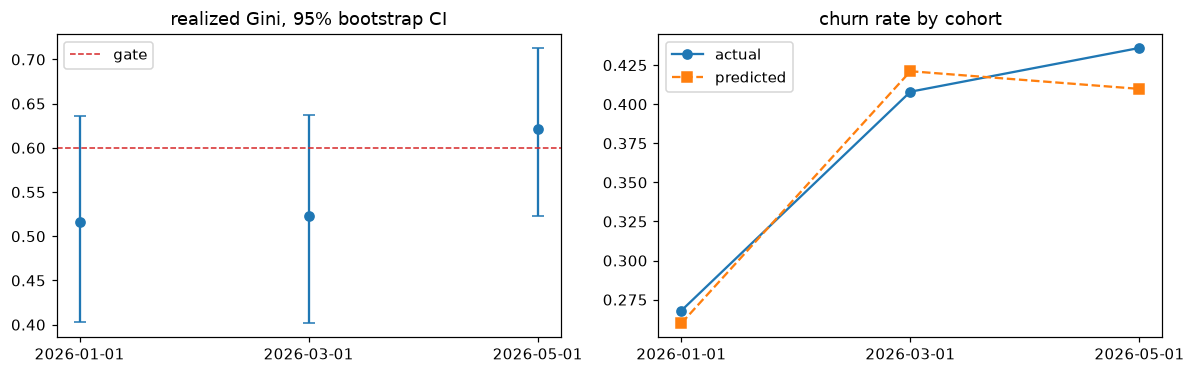

In [3]:
realized = pd.DataFrame([r["realized"] | {"as_of": r["as_of"]} for r in timeline if r["realized"]])
realized = realized.drop_duplicates("snapshot_date")
low = realized["gini_ci95"].str[0]
high = realized["gini_ci95"].str[1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].errorbar(realized["snapshot_date"], realized["gini"], yerr=[realized["gini"] - low, high - realized["gini"]], fmt="o", capsize=4)
axes[0].axhline(config.MIN_GINI, color="C3", ls="--", lw=1, label="gate")
axes[0].set_title("realized Gini, 95% bootstrap CI")
axes[0].legend()
axes[1].plot(realized["snapshot_date"], realized["churn_rate"], "o-", label="actual")
axes[1].plot(realized["snapshot_date"], realized["predicted_churn_rate"], "s--", label="predicted")
axes[1].set_title("churn rate by cohort")
axes[1].legend()
fig.tight_layout()
realized[["snapshot_date", "model_version", "rows", "gini", "gini_ci95", "churn_rate", "predicted_churn_rate"]]

Two things I take from this:

- **Two of the three point estimates are below the 0.60 gate, but none of the intervals is.** With 250 customers per cohort the realized Gini swings a lot from sampling alone. The retraining trigger requires the whole CI to be below the gate, so performance never fired it. Only drift did.
- **Calibration survives the population shift.** The churn rate in the cohorts jumped from ~27% to over 40%, and the predicted rate followed it closely. That's what keeps the expected-value decision rule usable as the base changes.

## Promotion decisions

In [4]:
decisions = pd.DataFrame([
    {
        "challenger": f"v{p['challenger']['version']}",
        "holdout_gini": p["challenger"]["gini"],
        "holdout_value": p["challenger"]["net_value"],
        "champion_value": p["champion"]["net_value"] if p["champion"] else None,
        "promoted": p["promoted"],
        "reason": p["reason"],
    }
    for p in promotions
])
decisions["value_delta_pct"] = (decisions["holdout_value"] / decisions["champion_value"] - 1) * 100
decisions

,challenger,holdout_gini,holdout_value,champion_value,promoted,reason,value_delta_pct
0,v1,0.667,61654.68,NaN,True,no champion yet,NaN
1,v2,0.673,61926.45,61654.68,True,"value $61,926 > $61,655, Gini within tolerance",0.441
2,v3,0.669,61719.33,61926.45,False,"value $61,719 <= champion $61,926",-0.334
3,v4,0.672,62363.49,61926.45,True,"value $62,363 > $61,926, Gini within tolerance",0.706


Every challenger passed the absolute gates. One was still rejected because it earned less than the champion on the frozen holdout.

The margins are worth being honest about: the promotions won by well under 1% of holdout value, which is inside sampling noise.
The next improvement is a paired bootstrap on the holdout, so a challenger is promoted only if it wins in at least 95% of resamples. It's the same reasoning the retraining trigger already uses.